In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = 'https://raw.githubusercontent.com/kkathait/D501_Final_Project/refs/heads/main/combined_data.csv'

df_premier = pd.read_csv(url)


In [3]:
teams = sorted(set(df_premier["HomeTeam"]) | set(df_premier["AwayTeam"]))

records = []

for team in teams:
    home_games = df_premier[df_premier["HomeTeam"] == team]
    
    home_wins = (home_games["FTR"] == "H").sum()
    home_losses = (home_games["FTR"] == "A").sum()
    home_draws = (home_games["FTR"] == "D").sum()
    
    away_games = df_premier[df_premier["AwayTeam"] == team]
    
    away_wins = (away_games["FTR"] == "A").sum()
    away_losses = (away_games["FTR"] == "H").sum()
    away_draws = (away_games["FTR"] == "D").sum()
    
    records.append({
        "Team": team,
        "Wins": home_wins + away_wins,
        "Losses": home_losses + away_losses,
        "Draws": home_draws + away_draws,
        "Games": home_wins + away_wins + home_losses + away_losses + home_draws + away_draws
    })

standings = pd.DataFrame(records)

standings = standings.sort_values("Games", ascending = False)

standings

,Team,Wins,Losses,Draws,Games
0,Arsenal,154,56,56,266
13,Liverpool,165,43,58,266
26,West Ham,91,114,61,266
23,Tottenham,115,99,52,266
17,Newcastle,107,96,63,266
16,Man United,127,74,65,266
15,Man City,182,41,43,266
1,Aston Villa,114,99,53,266
27,Wolves,81,124,61,266
8,Everton,86,110,70,266


In [4]:
standings["Points"] = (3 * standings["Wins"]) + standings["Draws"]

standings["Games"] = (standings["Wins"] + standings["Losses"] + standings["Draws"])

standings = standings.sort_values("Games", ascending = False)

standings

,Team,Wins,Losses,Draws,Games,Points
0,Arsenal,154,56,56,266,518
26,West Ham,91,114,61,266,334
23,Tottenham,115,99,52,266,397
17,Newcastle,107,96,63,266,384
16,Man United,127,74,65,266,446
15,Man City,182,41,43,266,589
1,Aston Villa,114,99,53,266,395
27,Wolves,81,124,61,266,304
8,Everton,86,110,70,266,328
7,Crystal Palace,82,103,81,266,327


In [5]:
# Calculate the number of matches officiated by each referee
referee_matches = df_premier.groupby("Referee").size().reset_index(name="Matches")

# Calculate the mean number of matches per referee
mean_matches = referee_matches["Matches"].mean()

print("Mean number of matches per referee:", mean_matches)

# Display referees and their match counts, sorted by matches officiated
referee_matches = referee_matches.sort_values("Matches", ascending=False)

referee_matches

Mean number of matches per referee: 60.45454545454545


,Referee,Matches
4,A Taylor,206
25,M Oliver,194
6,C Pawson,155
5,C Kavanagh,153
35,S Attwell,150
30,P Tierney,140
1,A Madley,131
37,S Hooper,130
29,P Bankes,115
31,R Jones,110


In [9]:
# Keep only referees who have officiated at least 60 matches
MIN_MATCHES = 60

established_referees = referee_analysis[
    referee_analysis["Matches"] >= MIN_MATCHES
].copy()

print("Number of referees with at least 60 matches:",
      len(established_referees))

# Display the remaining referees
established_referees

Number of referees with at least 60 matches: 21


,Referee,Matches,Avg_Yellow_Cards,Avg_Red_Cards,Avg_Goals,Home_Win_Rate,Away_Win_Rate,Draw_Rate,Avg_Home_Yellows,Avg_Away_Yellows,Avg_Home_Reds,Avg_Away_Reds
4,A Taylor,206,3.626214,0.135922,3.111650,38.834951,36.407767,24.757282,1.762136,1.864078,0.077670,0.058252
25,M Oliver,194,3.309278,0.118557,3.051546,41.237113,38.144330,20.618557,1.592784,1.716495,0.046392,0.072165
6,C Pawson,155,3.748387,0.103226,2.754839,40.000000,36.129032,23.870968,1.812903,1.935484,0.058065,0.045161
5,C Kavanagh,153,3.581699,0.117647,2.647059,42.483660,33.986928,23.529412,1.633987,1.947712,0.065359,0.052288
35,S Attwell,150,3.913333,0.133333,2.953333,44.666667,31.333333,24.000000,1.853333,2.060000,0.026667,0.106667
30,P Tierney,140,3.571429,0.128571,2.842857,40.000000,33.571429,26.428571,1.700000,1.871429,0.071429,0.057143
1,A Madley,131,3.351145,0.106870,2.954198,41.984733,33.587786,24.427481,1.473282,1.877863,0.061069,0.045802
37,S Hooper,130,3.738462,0.076923,3.015385,46.923077,27.692308,25.384615,1.653846,2.084615,0.053846,0.023077
29,P Bankes,115,3.939130,0.121739,2.643478,53.913043,24.347826,21.739130,1.660870,2.278261,0.052174,0.069565
31,R Jones,110,3.863636,0.100000,2.781818,47.272727,29.090909,23.636364,1.618182,2.245455,0.054545,0.045455


Dataset shape: (2660, 162)

Available columns:
['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BFDH', 'BFDD', 'BFDA', 'BMGMH', 'BMGMD', 'BMGMA', 'BVH', 'BVD', 'BVA', 'BWH', 'BWD', 'BWA', 'CLH', 'CLD', 'CLA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'BFEH', 'BFED', 'BFEA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'BFE>2.5', 'BFE<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'BFEAHH', 'BFEAHA', 'B365CH', 'B365CD', 'B365CA', 'BFDCH', 'BFDCD', 'BFDCA', 'BMGMCH', 'BMGMCD', 'BMGMCA', 'BVCH', 'BVCD', 'BVCA', 'BWCH', 'BWCD', 'BWCA', 'CLCH', 'CLCD', 'CLCA', 'LBCH', 'LBCD', 'LBCA', 'PSCH', 'PSCD', 'PSCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'BFECH', 'BFECD', 'BFECA', 'B365C>2.5', 'B365

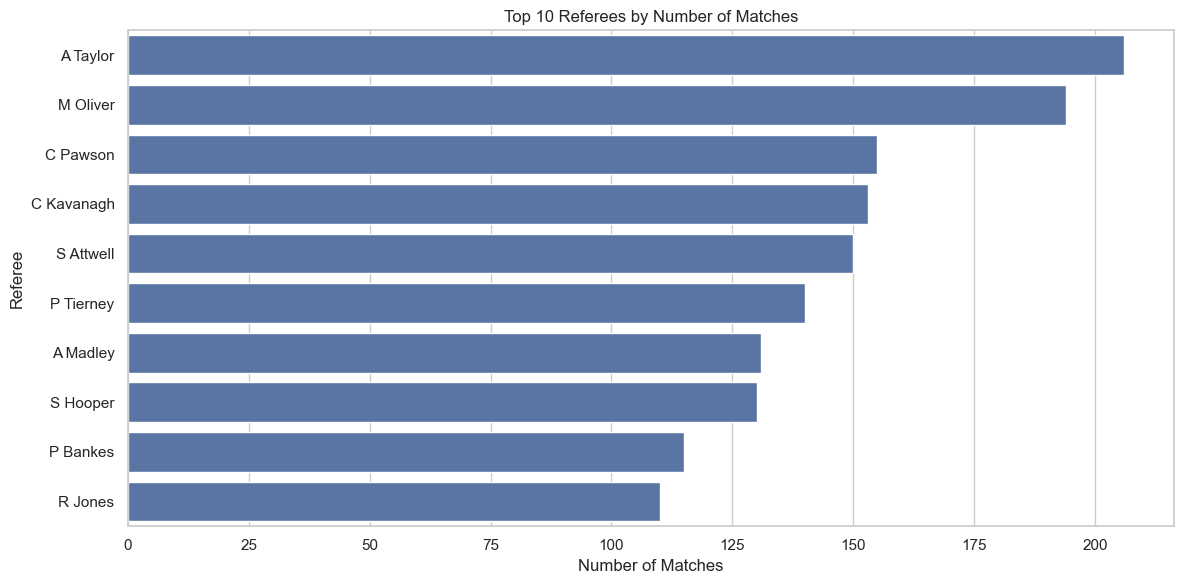


Referee analysis:
       Referee  Matches  Avg_Yellow_Cards  Avg_Red_Cards  Avg_Goals  \
4     A Taylor      206              3.63           0.14       3.11   
25    M Oliver      194              3.31           0.12       3.05   
6     C Pawson      155              3.75           0.10       2.75   
5   C Kavanagh      153              3.58           0.12       2.65   
35   S Attwell      150              3.91           0.13       2.95   
30   P Tierney      140              3.57           0.13       2.84   
1     A Madley      131              3.35           0.11       2.95   
37    S Hooper      130              3.74           0.08       3.02   
29    P Bankes      115              3.94           0.12       2.64   
31     R Jones      110              3.86           0.10       2.78   
8      D Coote      100              3.93           0.13       2.65   
9    D England       99              3.99           0.11       3.00   
14   J Gillett       84              3.74           0.05  

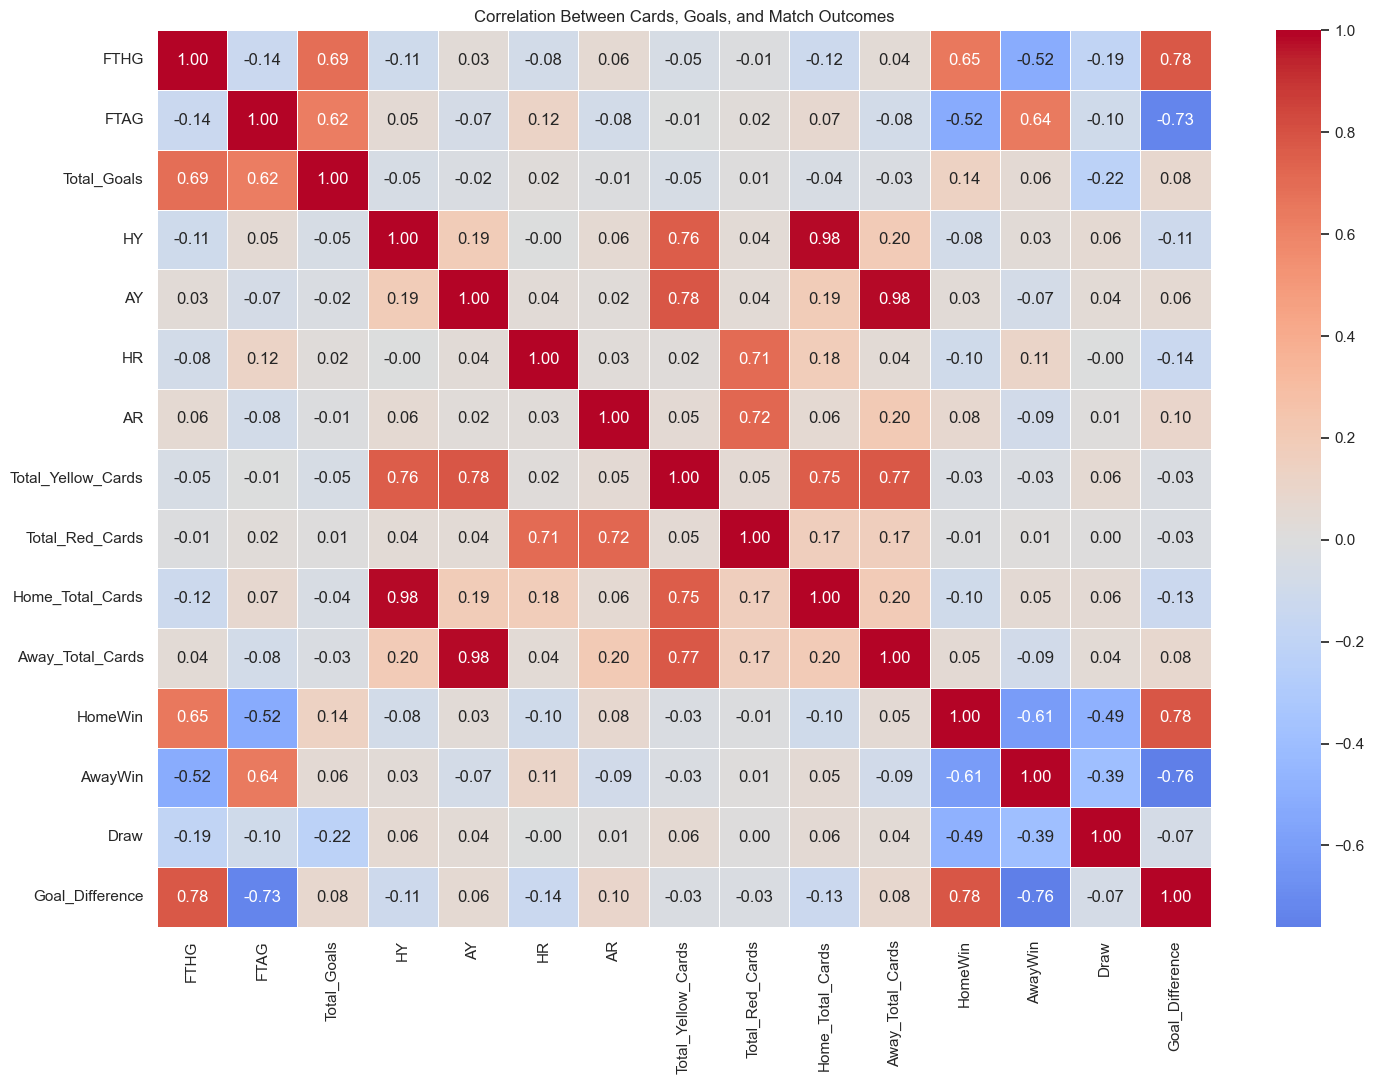


Average cards by match outcome:
  Match_Outcome  Avg_Yellow_Cards  Avg_Red_Cards  Matches
0      Away Win              3.52           0.12      876
1          Draw              3.83           0.12      629
2      Home Win              3.53           0.11     1155


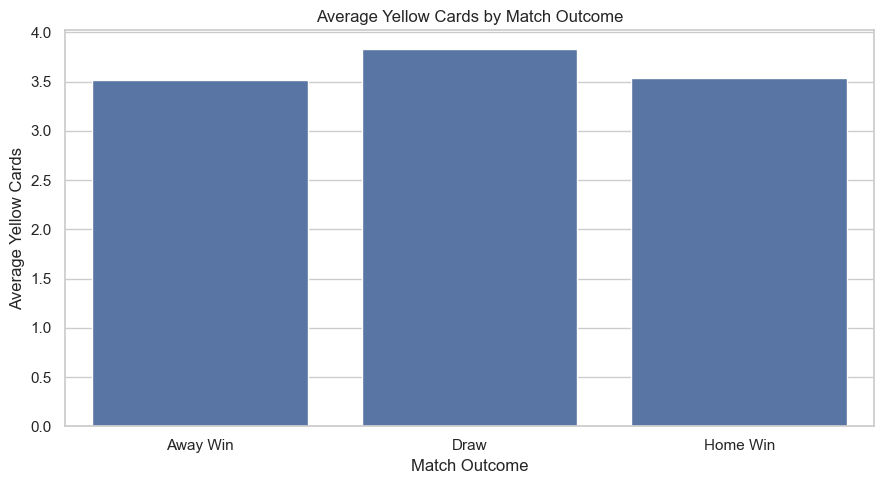

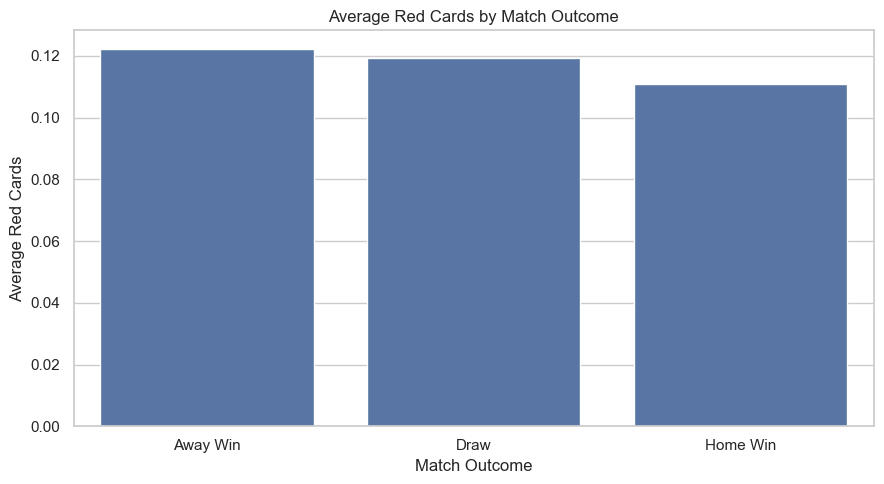

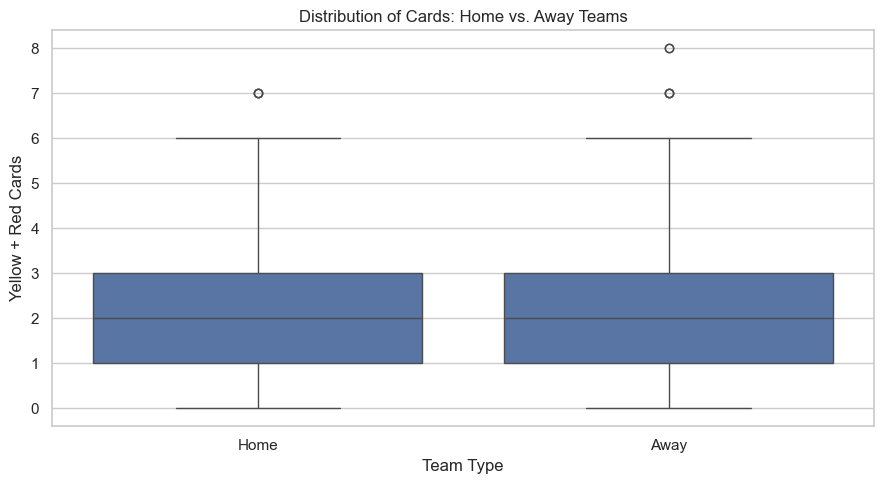


Average cards by team type:
           mean  median  count
Team_Type                     
Away       1.97     2.0   2660
Home       1.74     2.0   2660

Teams with the most red cards:
                Home_Red_Cards  Away_Red_Cards  Total_Red_Cards  Matches  \
Team                                                                       
Arsenal                      8              14               22      266   
Everton                     12               9               21      266   
Chelsea                      8              11               19      266   
Wolves                       8              10               18      266   
Tottenham                    8               9               17      266   
Brighton                     4              12               16      266   
West Ham                     5              11               16      266   
Crystal Palace               9               7               16      266   
Aston Villa                  7               7         

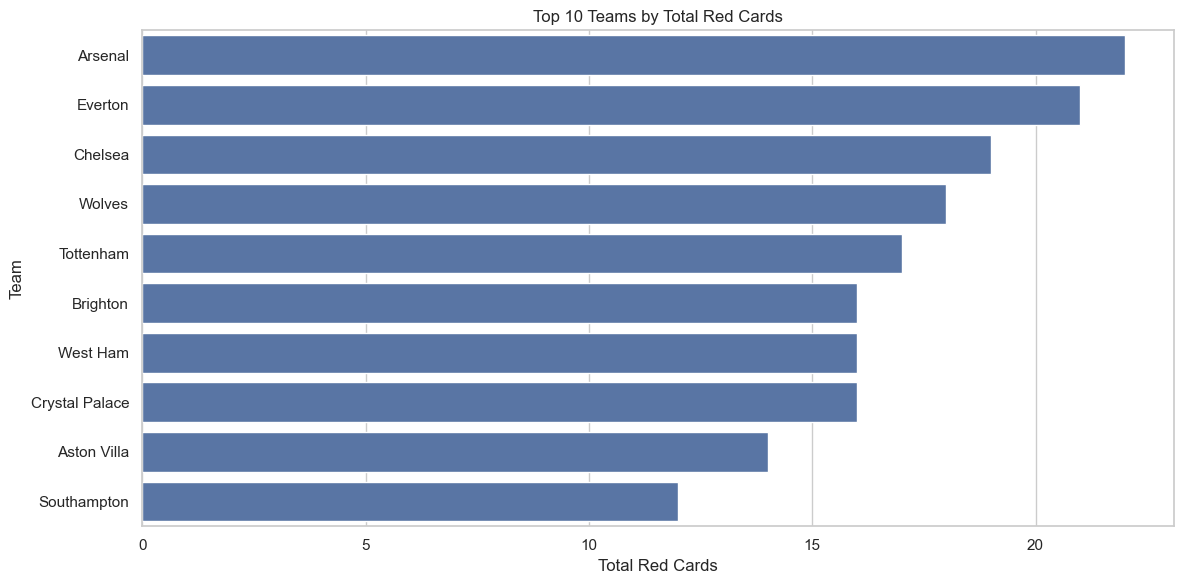

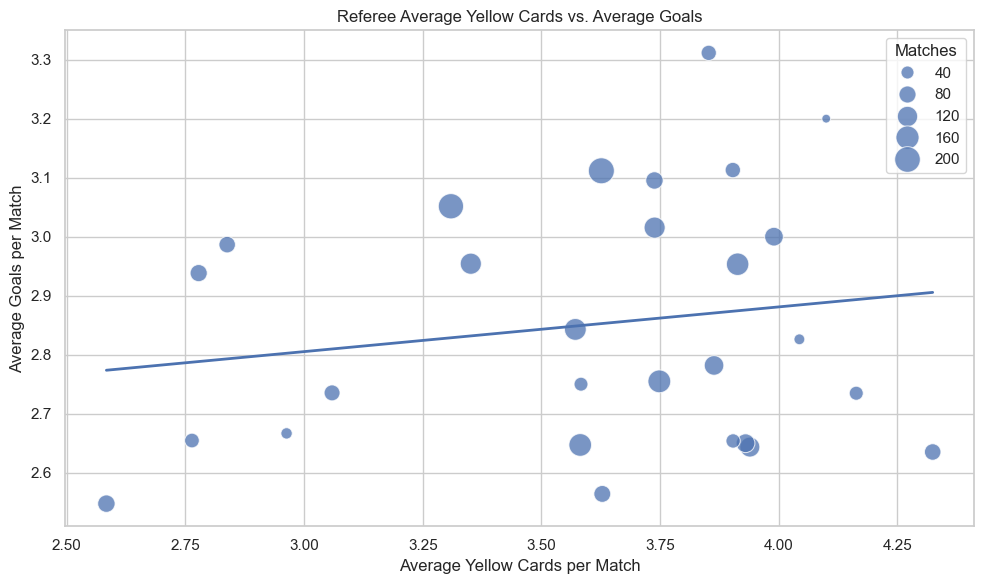

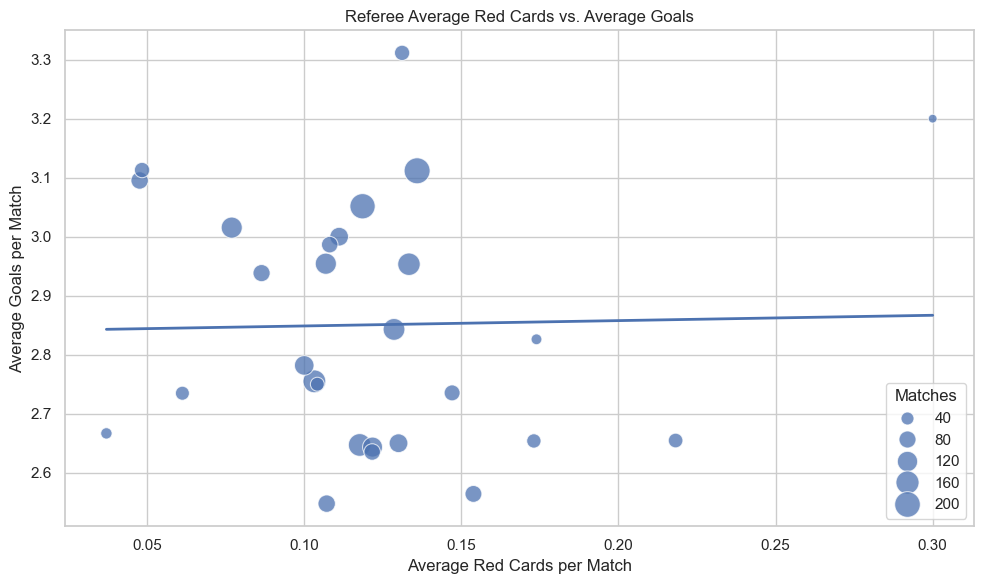

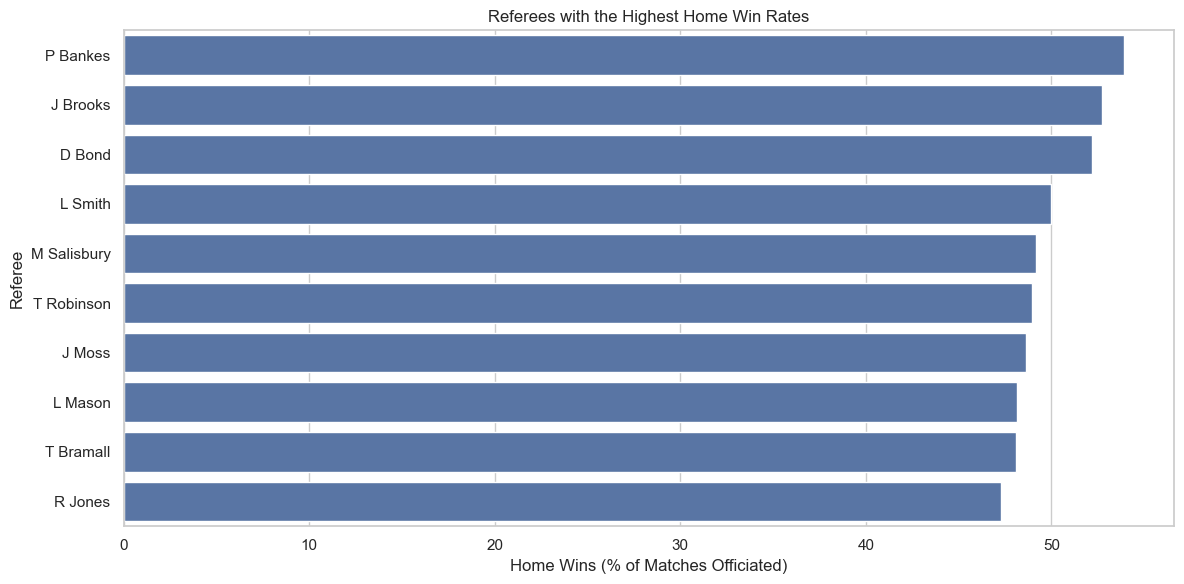

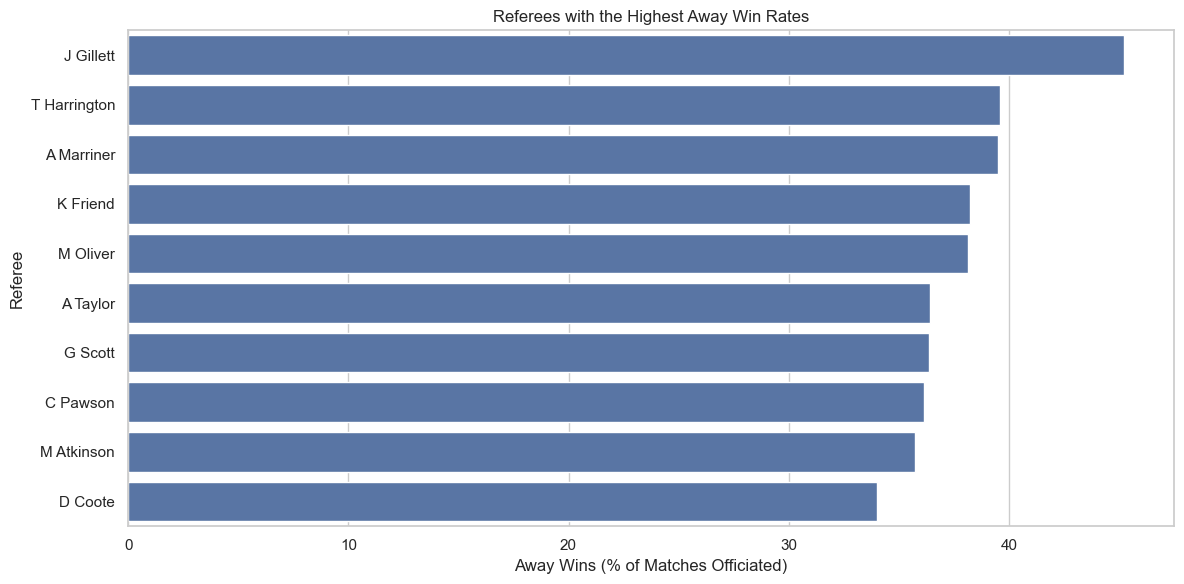


Home vs. away win-rate comparison:
        Referee  Matches  Home_Win_Rate  Away_Win_Rate  Home_Minus_Away
7        D Bond       23          52.17          21.74            30.43
21      L Smith       10          50.00          20.00            30.00
29     P Bankes      115          53.91          24.35            29.57
40    T Bramall       52          48.08          19.23            28.85
13     J Brooks       74          52.70          24.32            28.38
43   T Robinson       49          48.98          24.49            24.49
20      L Mason       27          48.15          25.93            22.22
37     S Hooper      130          46.92          27.69            19.23
31      R Jones      110          47.27          29.09            18.18
26  M Salisbury       61          49.18          31.15            18.03
16       J Moss       74          48.65          32.43            16.22
35    S Attwell      150          44.67          31.33            13.33
9     D England       99    


Strongest numeric correlations:
             Variable_1          Variable_2  Correlation
70                   AY    Away_Total_Cards        0.984
54                   HY    Home_Total_Cards        0.983
67                   AY  Total_Yellow_Cards        0.781
179             HomeWin     Goal_Difference        0.780
14                 FTHG     Goal_Difference        0.776
115  Total_Yellow_Cards    Away_Total_Cards        0.775
52                   HY  Total_Yellow_Cards        0.762
194             AwayWin     Goal_Difference       -0.760
114  Total_Yellow_Cards    Home_Total_Cards        0.753
29                 FTAG     Goal_Difference       -0.731
98                   AR     Total_Red_Cards        0.721
83                   HR     Total_Red_Cards        0.711
2                  FTHG         Total_Goals        0.690
11                 FTHG             HomeWin        0.653
27                 FTAG             AwayWin        0.637

Analysis complete!
Results saved as CSV files.


In [8]:

# ============================================================
# PREMIER LEAGUE FINAL PROJECT
# Referees, Cards, Goals, Teams, and Match Outcomes
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

# 2. LOAD THE DATASET
url = (
    "https://raw.githubusercontent.com/kkathait/"
    "D501_Final_Project/refs/heads/main/combined_data.csv"
)

df_premier = pd.read_csv(url)

# Standardize column names by removing accidental spaces
df_premier.columns = df_premier.columns.str.strip()

print("Dataset shape:", df_premier.shape)
print("\nAvailable columns:")
print(df_premier.columns.tolist())

# 3. CHECK REQUIRED COLUMNS
required_columns = [
    "HomeTeam", "AwayTeam", "FTR",
    "FTHG", "FTAG", "Referee"
]

missing_columns = [
    col for col in required_columns
    if col not in df_premier.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Identify card columns used in common football-data datasets.
# HY = home yellow cards, AY = away yellow cards
# HR = home red cards, AR = away red cards
card_candidates = ["HY", "AY", "HR", "AR"]

missing_cards = [
    col for col in card_candidates
    if col not in df_premier.columns
]

if missing_cards:
    raise ValueError(
        f"Card columns not found: {missing_cards}. "
        "Check the available columns and update their names."
    )

# Convert relevant columns to numeric values.
numeric_columns = [
    "FTHG", "FTAG", "HY", "AY", "HR", "AR"
]

for col in numeric_columns:
    df_premier[col] = pd.to_numeric(
        df_premier[col], errors="coerce"
    )

# Remove rows missing essential analysis values.
df_premier = df_premier.dropna(
    subset=required_columns + numeric_columns
).copy()

# Standardize outcome labels.
df_premier["FTR"] = (
    df_premier["FTR"].astype(str).str.strip().str.upper()
)

df_premier = df_premier[
    df_premier["FTR"].isin(["H", "D", "A"])
].copy()

# 4. CREATE NEW ANALYSIS COLUMNS

# Total goals and cards in each match
df_premier["Total_Goals"] = (
    df_premier["FTHG"] + df_premier["FTAG"]
)

df_premier["Total_Yellow_Cards"] = (
    df_premier["HY"] + df_premier["AY"]
)

df_premier["Total_Red_Cards"] = (
    df_premier["HR"] + df_premier["AR"]
)

# Total cards received by each side
df_premier["Home_Total_Cards"] = (
    df_premier["HY"] + df_premier["HR"]
)

df_premier["Away_Total_Cards"] = (
    df_premier["AY"] + df_premier["AR"]
)

# Binary match outcomes: 1 = true, 0 = false
df_premier["HomeWin"] = (
    df_premier["FTR"] == "H"
).astype(int)

df_premier["AwayWin"] = (
    df_premier["FTR"] == "A"
).astype(int)

df_premier["Draw"] = (
    df_premier["FTR"] == "D"
).astype(int)

# Goal difference from the home team's perspective
df_premier["Goal_Difference"] = (
    df_premier["FTHG"] - df_premier["FTAG"]
)

print("\nSample of prepared data:")
print(df_premier.head())


# ============================================================
# ANALYSIS 1: MEAN NUMBER OF MATCHES PER REFEREE
# ============================================================

# Count the matches officiated by each referee.
referee_matches = (
    df_premier.groupby("Referee")
    .size()
    .reset_index(name="Matches")
    .sort_values("Matches", ascending=False)
)

# Calculate the average workload across referees.
mean_matches = referee_matches["Matches"].mean()

print("\nMean matches per referee:", round(mean_matches, 2))
print("\nReferees with the most matches:")
print(referee_matches.head(10))

# Visualize the 10 referees who officiated the most matches.
top_referees = referee_matches.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_referees,
    x="Matches",
    y="Referee"
)
plt.title("Top 10 Referees by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Referee")
plt.tight_layout()
plt.show()


# ============================================================
# ANALYSIS 2: REFEREE STATISTICS AND HOME/AWAY WIN RATES
# ============================================================

# Calculate match-level averages and outcome rates for each referee.
referee_analysis = (
    df_premier.groupby("Referee")
    .agg(
        Matches=("FTR", "size"),
        Avg_Yellow_Cards=("Total_Yellow_Cards", "mean"),
        Avg_Red_Cards=("Total_Red_Cards", "mean"),
        Avg_Goals=("Total_Goals", "mean"),
        Home_Win_Rate=("HomeWin", "mean"),
        Away_Win_Rate=("AwayWin", "mean"),
        Draw_Rate=("Draw", "mean"),
        Avg_Home_Yellows=("HY", "mean"),
        Avg_Away_Yellows=("AY", "mean"),
        Avg_Home_Reds=("HR", "mean"),
        Avg_Away_Reds=("AR", "mean")
    )
    .reset_index()
)

# Express rates as percentages.
rate_columns = [
    "Home_Win_Rate", "Away_Win_Rate", "Draw_Rate"
]

referee_analysis[rate_columns] *= 100

# Sort by matches to inspect referees with larger sample sizes.
referee_analysis = referee_analysis.sort_values(
    "Matches", ascending=False
)

print("\nReferee analysis:")
print(referee_analysis.head(15).round(2))

# Only compare referees with at least 10 matches to reduce
# misleading extremes caused by very small samples.
MIN_MATCHES = 10

established_referees = referee_analysis[
    referee_analysis["Matches"] >= MIN_MATCHES
].copy()

print(
    f"\nReferees included in comparisons "
    f"(at least {MIN_MATCHES} matches):",
    len(established_referees)
)


# ============================================================
# ANALYSIS 3: CORRELATION BETWEEN CARDS, GOALS, AND OUTCOMES
# ============================================================

# Select numeric variables relevant to the project.
correlation_columns = [
    "FTHG", "FTAG", "Total_Goals",
    "HY", "AY", "HR", "AR",
    "Total_Yellow_Cards", "Total_Red_Cards",
    "Home_Total_Cards", "Away_Total_Cards",
    "HomeWin", "AwayWin", "Draw",
    "Goal_Difference"
]

# Pearson correlation measures linear association.
correlation_matrix = df_premier[
    correlation_columns
].corr(method="pearson")

print("\nCorrelation matrix:")
print(correlation_matrix.round(2))

# Display a heatmap of the correlations.
plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Cards, Goals, and Match Outcomes")
plt.tight_layout()
plt.show()


# ============================================================
# ANALYSIS 4: DO MORE CARDS RELATE TO MATCH OUTCOMES?
# ============================================================

# Convert the match outcome codes into readable labels.
outcome_labels = {
    "H": "Home Win",
    "D": "Draw",
    "A": "Away Win"
}

df_premier["Match_Outcome"] = (
    df_premier["FTR"].map(outcome_labels)
)

# Compare average cards across match outcomes.
cards_by_outcome = (
    df_premier.groupby("Match_Outcome")
    .agg(
        Avg_Yellow_Cards=("Total_Yellow_Cards", "mean"),
        Avg_Red_Cards=("Total_Red_Cards", "mean"),
        Matches=("FTR", "size")
    )
    .reset_index()
)

print("\nAverage cards by match outcome:")
print(cards_by_outcome.round(2))

# Plot average yellow cards for each outcome.
plt.figure(figsize=(9, 5))
sns.barplot(
    data=cards_by_outcome,
    x="Match_Outcome",
    y="Avg_Yellow_Cards"
)
plt.title("Average Yellow Cards by Match Outcome")
plt.xlabel("Match Outcome")
plt.ylabel("Average Yellow Cards")
plt.tight_layout()
plt.show()

# Plot average red cards for each outcome.
plt.figure(figsize=(9, 5))
sns.barplot(
    data=cards_by_outcome,
    x="Match_Outcome",
    y="Avg_Red_Cards"
)
plt.title("Average Red Cards by Match Outcome")
plt.xlabel("Match Outcome")
plt.ylabel("Average Red Cards")
plt.tight_layout()
plt.show()


# ============================================================
# ANALYSIS 5: HOME VS. AWAY TEAM CARD COMPARISON
# ============================================================

# Reshape home and away card totals into a single table.
home_cards = df_premier[
    ["Home_Total_Cards"]
].rename(columns={"Home_Total_Cards": "Cards"})

home_cards["Team_Type"] = "Home"

away_cards = df_premier[
    ["Away_Total_Cards"]
].rename(columns={"Away_Total_Cards": "Cards"})

away_cards["Team_Type"] = "Away"

side_cards = pd.concat(
    [home_cards, away_cards],
    ignore_index=True
)

# Compare the distribution of cards received by home and away sides.
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=side_cards,
    x="Team_Type",
    y="Cards"
)
plt.title("Distribution of Cards: Home vs. Away Teams")
plt.xlabel("Team Type")
plt.ylabel("Yellow + Red Cards")
plt.tight_layout()
plt.show()

print("\nAverage cards by team type:")
print(
    side_cards.groupby("Team_Type")["Cards"]
    .agg(["mean", "median", "count"])
    .round(2)
)


# ============================================================
# ANALYSIS 6: WHICH TEAMS RECEIVE THE MOST RED CARDS?
# ============================================================

# Count red cards received by teams when playing at home.
home_reds = (
    df_premier.groupby("HomeTeam")["HR"]
    .sum()
    .rename_axis("Team")
    .rename("Home_Red_Cards")
)

# Count red cards received by teams when playing away.
away_reds = (
    df_premier.groupby("AwayTeam")["AR"]
    .sum()
    .rename_axis("Team")
    .rename("Away_Red_Cards")
)

# Combine home and away red-card totals.
team_red_cards = pd.concat(
    [home_reds, away_reds], axis=1
).fillna(0)

team_red_cards["Total_Red_Cards"] = (
    team_red_cards["Home_Red_Cards"]
    + team_red_cards["Away_Red_Cards"]
)

# Count the number of home and away appearances for each team.
home_appearances = (
    df_premier["HomeTeam"].value_counts()
)

away_appearances = (
    df_premier["AwayTeam"].value_counts()
)

team_red_cards["Matches"] = (
    home_appearances.add(away_appearances, fill_value=0)
)

# Calculate red cards per match for fairer comparisons.
team_red_cards["Red_Cards_Per_Match"] = (
    team_red_cards["Total_Red_Cards"]
    / team_red_cards["Matches"]
)

team_red_cards = team_red_cards.sort_values(
    "Total_Red_Cards", ascending=False
)

print("\nTeams with the most red cards:")
print(team_red_cards.head(15).round(3))

# Plot the 10 teams with the highest total red-card counts.
top_red_card_teams = team_red_cards.head(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_red_card_teams,
    x="Total_Red_Cards",
    y="Team"
)
plt.title("Top 10 Teams by Total Red Cards")
plt.xlabel("Total Red Cards")
plt.ylabel("Team")
plt.tight_layout()
plt.show()


# ============================================================
# ANALYSIS 7: REFEREE CARDS VS. AVERAGE GOALS
# ============================================================

# Each point represents one referee.
# The point size represents the number of matches officiated.
# A fitted line summarizes the linear trend.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=established_referees,
    x="Avg_Yellow_Cards",
    y="Avg_Goals",
    scatter=False,
    ci=None,
    line_kws={"linewidth": 2}
)

sns.scatterplot(
    data=established_referees,
    x="Avg_Yellow_Cards",
    y="Avg_Goals",
    size="Matches",
    sizes=(40, 350),
    alpha=0.75,
    legend="brief"
)

plt.title("Referee Average Yellow Cards vs. Average Goals")
plt.xlabel("Average Yellow Cards per Match")
plt.ylabel("Average Goals per Match")
plt.tight_layout()
plt.show()

# Also investigate the association with red cards.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=established_referees,
    x="Avg_Red_Cards",
    y="Avg_Goals",
    scatter=False,
    ci=None,
    line_kws={"linewidth": 2}
)

sns.scatterplot(
    data=established_referees,
    x="Avg_Red_Cards",
    y="Avg_Goals",
    size="Matches",
    sizes=(40, 350),
    alpha=0.75
)

plt.title("Referee Average Red Cards vs. Average Goals")
plt.xlabel("Average Red Cards per Match")
plt.ylabel("Average Goals per Match")
plt.tight_layout()
plt.show()


# ============================================================
# ANALYSIS 8: HOME AND AWAY WIN RATES BY REFEREE
# ============================================================

# Use only referees with enough matches for a more stable comparison.
# These are observed win rates, not model-predicted probabilities.
win_rates = established_referees.sort_values(
    "Home_Win_Rate", ascending=False
)

# Show the 10 highest home-win rates.
top_home_rates = win_rates.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_home_rates,
    x="Home_Win_Rate",
    y="Referee"
)
plt.title("Referees with the Highest Home Win Rates")
plt.xlabel("Home Wins (% of Matches Officiated)")
plt.ylabel("Referee")
plt.tight_layout()
plt.show()

# Show the 10 highest away-win rates.
top_away_rates = established_referees.sort_values(
    "Away_Win_Rate", ascending=False
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_away_rates,
    x="Away_Win_Rate",
    y="Referee"
)
plt.title("Referees with the Highest Away Win Rates")
plt.xlabel("Away Wins (% of Matches Officiated)")
plt.ylabel("Referee")
plt.tight_layout()
plt.show()

# Compare home and away win rates for the same referees.
win_rate_comparison = established_referees[
    ["Referee", "Matches", "Home_Win_Rate", "Away_Win_Rate"]
].copy()

win_rate_comparison["Home_Minus_Away"] = (
    win_rate_comparison["Home_Win_Rate"]
    - win_rate_comparison["Away_Win_Rate"]
)

print("\nHome vs. away win-rate comparison:")
print(
    win_rate_comparison.sort_values(
        "Home_Minus_Away", ascending=False
    ).round(2).head(15)
)


# ============================================================
# ANALYSIS 9: INTERACTIVE REFEREE COMPARISON
# ============================================================

# Interactive chart to explore average cards, goals, and match counts.
fig = px.scatter(
    established_referees,
    x="Avg_Yellow_Cards",
    y="Avg_Goals",
    size="Matches",
    color="Home_Win_Rate",
    hover_name="Referee",
    hover_data=[
        "Avg_Red_Cards",
        "Away_Win_Rate",
        "Draw_Rate",
        "Matches"
    ],
    title="Referee Comparison: Cards, Goals, and Home Win Rate",
    labels={
        "Avg_Yellow_Cards": "Average Yellow Cards per Match",
        "Avg_Goals": "Average Goals per Match",
        "Matches": "Matches Officiated",
        "Home_Win_Rate": "Home Win Rate (%)",
        "Away_Win_Rate": "Away Win Rate (%)",
        "Draw_Rate": "Draw Rate (%)",
        "Avg_Red_Cards": "Average Red Cards per Match"
    }
)

fig.show()


# ============================================================
# ANALYSIS 10: FIND THE STRONGEST NUMERIC CORRELATIONS
# ============================================================

# Exclude the diagonal (each variable correlated with itself)
# and retain only unique variable pairs.
correlation_pairs = (
    correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape), k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Variable_1", "Variable_2", "Correlation"
]

# Sort by absolute correlation strength.
correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

strongest_correlations = correlation_pairs.sort_values(
    "Absolute_Correlation", ascending=False
)

print("\nStrongest numeric correlations:")
print(
    strongest_correlations[
        ["Variable_1", "Variable_2", "Correlation"]
    ].head(15).round(3)
)


# ============================================================
# ANALYSIS 11: SAVE RESULTS FOR THE FINAL PROJECT
# ============================================================

# Save tables so they can be reused in reports or visualizations.
referee_matches.to_csv(
    "referee_match_counts.csv", index=False
)

referee_analysis.to_csv(
    "referee_analysis.csv", index=False
)

team_red_cards.to_csv(
    "team_red_card_analysis.csv"
)

correlation_matrix.to_csv(
    "match_correlation_matrix.csv"
)

correlation_pairs.to_csv(
    "correlation_pairs.csv", index=False
)

print("\nAnalysis complete!")
print("Results saved as CSV files.")
